# §6.1 Illustrative Trajectories

Single-panel stacked-area figure for the EMNLP paper showing cluster-level sense trajectories.

**Lemma:** `Start`  
**Time range:** 1910–1990 (1900 dropped — too sparse, n=8)  
**Smoothing:** centred 3-decade rolling mean (visualisation only)

**Inputs:**
- `data/processed/diachronic/aggregated/pilot_v3_coarse_sense_counts.csv`
- `data/processed/germanet/sense_clusters_reviewed.json`

**Output:** `figures/trajectories_examples.pdf`

## 1. Imports & paths

In [13]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Resolve repo root no matter where the notebook is opened from
BASE = Path.cwd()
while not (BASE / "data").is_dir() and BASE != BASE.parent:
    BASE = BASE.parent
print(f"Repo root: {BASE}")

COUNTS_FILE   = BASE / "data/processed/diachronic/aggregated/pilot_v3_coarse_sense_counts.csv"
CLUSTERS_FILE = BASE / "data/processed/germanet/sense_clusters_reviewed.json"
OUTPUT_FILE   = BASE / "figures/trajectories_examples.pdf"

for p in (COUNTS_FILE, CLUSTERS_FILE):
    assert p.exists(), f"missing input: {p}"
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

Repo root: /Users/paulschmitt/DataspellProjects/Worde-Sense-Disambiguation


## 2. Configuration

Edit these to switch lemmas, time range, smoothing window, or legend overrides.

In [20]:
LEMMAS         = ["Präsident"]
DECADE_MIN     = 1910
DECADE_MAX     = 1990
SMOOTH_WINDOW  = 3   # centred rolling mean window for visualisation only

# Optional: override the JSON labels for the legend without touching the canonical file.
# Leave empty {} to use the raw labels from sense_clusters_reviewed.json.
LEGEND_OVERRIDES: dict[str, dict[str, str]] = {
    # e.g. "Start": {"Start_c2": "Startlinie / Sport"}
}

PALETTES = [plt.cm.tab10.colors, plt.cm.Set2.colors]

## 3. Load data

In [21]:
counts = pd.read_csv(COUNTS_FILE)
with CLUSTERS_FILE.open(encoding="utf-8") as f:
    clusters = json.load(f)

print(f"counts: {len(counts):,} rows, {counts['lemma'].nunique()} lemmas")
print(f"clusters JSON: {len(clusters)} lemmas")
for lemma in LEMMAS:
    assert lemma in clusters, f"{lemma} missing in clusters JSON"
    cluster_dict = clusters[lemma]["clusters"]
    print(f"\n{lemma}: {len(cluster_dict)} clusters")
    for cid, payload in sorted(cluster_dict.items()):
        print(f"  {cid:<14} → {payload['label']}")

counts: 10,497 rows, 502 lemmas
clusters JSON: 503 lemmas

Präsident: 2 clusters
  Präsident_c0   → Präsident einer Organisation
  Präsident_c1   → Staatspräsident


## 4. Helper functions

In [22]:
def trajectory_table(counts: pd.DataFrame, lemma: str,
                     decade_min: int = DECADE_MIN,
                     decade_max: int = DECADE_MAX) -> pd.DataFrame:
    """Wide proportion table (rows=cluster, cols=decade) for the given lemma."""
    sub = counts[counts["lemma"] == lemma]
    wide = (sub.pivot_table(index="predicted_sense_id",
                            columns="decade",
                            values="proportion",
                            aggfunc="sum")
              .fillna(0.0))
    decades = [d for d in sorted(wide.columns) if decade_min <= int(d) <= decade_max]
    return wide[decades]


def smooth(wide: pd.DataFrame, window: int = SMOOTH_WINDOW) -> pd.DataFrame:
    """Centred rolling mean along the decade axis. Edges use min_periods=1."""
    return wide.T.rolling(window=window, center=True, min_periods=1).mean().T


def order_clusters_by_mass(wide: pd.DataFrame) -> list[str]:
    """Largest mean proportion first → drawn at bottom of stack."""
    return wide.mean(axis=1).sort_values(ascending=False).index.tolist()


def label_for(lemma: str, cid: str) -> str:
    """Legend text: override if present, else canonical label from JSON."""
    override = LEGEND_OVERRIDES.get(lemma, {}).get(cid)
    return override if override else clusters[lemma]["clusters"][cid]["label"]

## 5. Build the figure

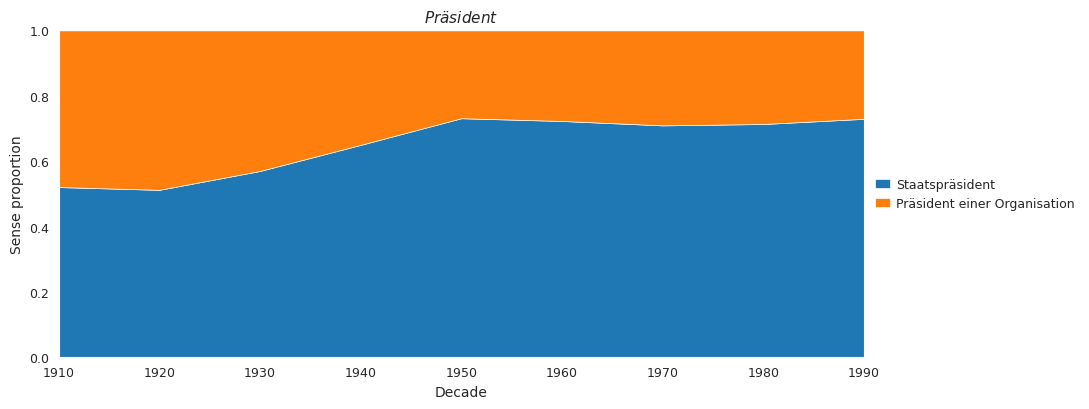

In [23]:
plt.rcParams.update({
    "font.family":     "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.titlesize":  11,
    "axes.labelsize":  10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

fig, axes = plt.subplots(1, len(LEMMAS), figsize=(11, 4.2), sharey=True)
if len(LEMMAS) == 1:
    axes = [axes]

for ax, lemma, palette in zip(axes, LEMMAS, PALETTES):
    wide        = trajectory_table(counts, lemma)
    smooth_wide = smooth(wide)
    order       = order_clusters_by_mass(smooth_wide)
    smooth_wide = smooth_wide.loc[order]
    decades     = [int(d) for d in smooth_wide.columns]

    ax.stackplot(
        decades,
        smooth_wide.values,
        labels=[label_for(lemma, cid) for cid in order],
        colors=palette[:len(order)],
        edgecolor="white",
        linewidth=0.5,
    )
    ax.set_xlim(DECADE_MIN, DECADE_MAX)
    ax.set_ylim(0.0, 1.0)
    ax.set_xticks(list(range(DECADE_MIN, DECADE_MAX + 1, 10)))
    ax.set_xlabel("Decade")
    ax.set_title(f"$\\it{{{lemma}}}$")
    ax.tick_params(axis="both", direction="out", length=3)
    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        frameon=False,
        handlelength=1.2,
        handletextpad=0.5,
    )

axes[0].set_ylabel("Sense proportion")
fig.tight_layout()
plt.show()

## 6. Save

In [6]:
fig.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
size_kb = OUTPUT_FILE.stat().st_size / 1024
print(f"Wrote: {OUTPUT_FILE.relative_to(BASE)}  ({size_kb:.1f} KB)")

Wrote: figures/trajectories_examples.pdf  (22.3 KB)


## 7. Sanity check — print n_contexts per decade

Useful for spotting sparse decades that you might want to drop from a published figure.

In [7]:
STATS_FILE = BASE / "data/processed/diachronic/aggregated/pilot_v3_coarse_stats.csv"
stats = pd.read_csv(STATS_FILE)
for lemma in LEMMAS:
    sub = (stats[stats["lemma"] == lemma]
           .set_index("decade")["n_contexts"]
           .reindex(range(DECADE_MIN, DECADE_MAX + 1, 10))
           .fillna(0).astype(int))
    print(f"{lemma}: {dict(sub)}")

Start: {1910: np.int64(14), 1920: np.int64(37), 1930: np.int64(54), 1940: np.int64(25), 1950: np.int64(46), 1960: np.int64(58), 1970: np.int64(51), 1980: np.int64(64), 1990: np.int64(72)}
Schlüssel: {1910: np.int64(86), 1920: np.int64(95), 1930: np.int64(85), 1940: np.int64(48), 1950: np.int64(77), 1960: np.int64(60), 1970: np.int64(60), 1980: np.int64(70), 1990: np.int64(64)}
